# Taller de PLN: modelo de lenguaje y traducción seq2seq

**Integrantes:** _Oscar Iván García Montañez, Juan David Cuintaco Naranjo, Santiago Serrano, Juan Felipe Pardo Quintana_

**Curso:** Procesamiento de Lenguaje Natural


## 0. Configuración del entorno

Sube a Colab estos dos archivos:

- `cien_anos_de_soledad_completo.txt`
- `Combined Data es-ES.csv`

Si no están en `/content`, la celda de verificación abrirá el selector de archivos.

El notebook usa Keras con backend **TensorFlow**, que es el entorno estable de
Colab para este taller.


In [ ]:
# Dependencias del taller
!pip install -q --upgrade keras sacrebleu rouge-score


In [ ]:
# Keras usará TensorFlow; debe configurarse antes de importar keras
import os
os.environ["KERAS_BACKEND"] = "tensorflow"


In [ ]:
import json
import platform
import random
import re
import shutil
import string
import time
import unicodedata
from collections import Counter
from pathlib import Path

# TensorFlow es el backend de Keras y también se usa en TextVectorization
try:
    import tensorflow as tf
except ImportError:
    !pip install -q tensorflow
    import tensorflow as tf

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from keras import layers

# Permite que TensorFlow crezca la memoria de la GPU según la necesite
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception as exc:
        print("No se pudo configurar la memoria de la GPU:", exc)

SEED = 42
keras.utils.set_random_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

print("Backend de Keras:", keras.backend.backend())
print("TensorFlow:", tf.__version__)
print("GPUs disponibles:", [gpu.name for gpu in tf.config.list_physical_devices("GPU")])


Backend de Keras: tensorflow
TensorFlow: 2.21.0
GPUs disponibles: ['/physical_device:GPU:0']


In [ ]:
# Configuración general
MODO_PRUEBA = False   # True: corrida rápida con pocos datos y 1 época
SEED = 42
BASE = Path("/content") if Path("/content").exists() else Path.cwd()
RESULTADOS = BASE / "resultados_taller"
FIGURAS = RESULTADOS / "figuras"
for carpeta in (RESULTADOS, FIGURAS):
    carpeta.mkdir(parents=True, exist_ok=True)

RUTA_LIBRO = BASE / "cien_anos_de_soledad_completo.txt"
RUTA_DATASET = BASE / "Combined Data es-ES.csv"

# Parte 1: modelo de lenguaje
LM_EPOCAS = 2 if MODO_PRUEBA else 30
LM_SEQ_LEN = 100

# Parte 2: traducción español -> inglés
MT_MAX_LEN = 50          # palabras por fragmento (incluye [start] y [end])
MT_VOCAB = 20_000
MT_BATCH = 64
MT_EPOCAS = 1 if MODO_PRUEBA else 10
MT_MAX_PARES_PRUEBA = 1_000

print("Modo prueba:", MODO_PRUEBA)
print("Resultados en:", RESULTADOS.resolve())


Modo prueba: False
Resultados en: /content/resultados_taller


In [ ]:
def asegurar_archivo(ruta):
    """Comprueba que el archivo exista; si no, permite subirlo en Colab."""
    if ruta.exists():
        return
    try:
        from google.colab import files
        print(f"Sube el archivo: {ruta.name}")
        files.upload()
    except Exception as exc:
        raise FileNotFoundError(f"No se encontró {ruta}") from exc

asegurar_archivo(RUTA_LIBRO)
asegurar_archivo(RUTA_DATASET)
print("Libro:", RUTA_LIBRO, "->", RUTA_LIBRO.exists())
print("Dataset:", RUTA_DATASET, "->", RUTA_DATASET.exists())


Libro: /content/cien_anos_de_soledad_completo.txt -> True
Dataset: /content/Combined Data es-ES.csv -> True


# Parte 1. Modelo de lenguaje con *Cien años de soledad*

Se entrena una GRU a nivel de carácter. El modelo aprende a predecir el
siguiente carácter y luego se usa para generar texto a partir de un prompt.


## 1.1 Carga y limpieza del texto

El archivo proviene de un OCR, así que se corrigen errores, se quitan
cabeceras, números de página e índice, y se reconstruyen los párrafos.


In [ ]:
raw = RUTA_LIBRO.read_text(encoding="utf-8-sig")
print(f"{len(raw):,} caracteres | {raw.count(chr(10)):,} líneas")

827,487 caracteres | 9,585 líneas


In [ ]:
import re, string, unicodedata, collections

# Correcciones de OCR verificadas una a una en el texto
CORRECCIONES_OCR = {
    "podere 5 del huevo": "poderes del huevo",
    "Remedios 8n la": "Remedios en la",
    "-1Aureliano!": "-¡Aureliano!",
    "do8 soldados": "dos soldados",
    ";f~½cionaron": "funcionaron",
    "pu6blo": "pueblo",
    "descubría 105 muslos": "descubría los muslos",
    "de 105 últimos meses": "de los últimos meses",
    "nill 0 asustado": "niño asustado",
    "José 5<bía": "José sabía",
    # compuestos con guion que el des-guionado fusiona
    "niñosen-cruz": "niños-en-cruz",
    "hombrevíbora": "hombre-víbora",
}
PERMITIDOS = set(string.ascii_letters + string.digits + "áéíóúüñÁÉÍÓÚÜÑ¡¿«» \n" + ".,;:!?()-\"'")


def limpiar_libro(raw, ancho_corto=84):
    """Devuelve (texto_limpio, parrafos, reporte)."""
    rep = {}
    t = unicodedata.normalize("NFC", raw).replace("\xa0", " ").replace("\r\n", "\n")
    lineas = [l.strip() for l in t.split("\n")]
    rep["lineas_originales"] = len(lineas)

    # 1) Recortar portada/dedicatoria (hasta el capítulo "I") e índice final (puntos guía)
    ini = next(i for i, l in enumerate(lineas) if l == "I")
    fin = next(i for i, l in enumerate(lineas) if re.search(r"\.{5,}", l))
    rep["lineas_antes_del_cap_I"] = ini
    rep["lineas_del_indice_y_cola"] = len(lineas) - fin
    cuerpo = lineas[ini:fin]

    # 2) Quitar cabeceras, números de página y marcas de capítulo
    cabeceras = {"Cien años de soledad", "Gabriel García Márquez"}
    limpias, n_cab, n_pag, n_cap = [], 0, 0, 0
    for l in cuerpo:
        norm = re.sub(r"\s+", " ", l)
        if norm in cabeceras:
            n_cab += 1
        elif re.fullmatch(r"\d{1,3}", l):
            n_pag += 1
        elif re.fullmatch(r"[IVXL]+", l):
            n_cap += 1
            limpias.append("")          # el capítulo queda como corte de párrafo
        else:
            limpias.append(l)
    rep.update(cabeceras_quitadas=n_cab, numeros_de_pagina_quitados=n_pag, capitulos=n_cap)

    # 3) Reconstruir párrafos: des-guionar, unir líneas, cortar en líneas cortas con puntuación final
    parrafos, cur, n_guion = [], "", 0

    def cerrar():
        nonlocal cur
        if cur.strip():
            parrafos.append(cur.strip())
        cur = ""

    for l in limpias:
        if l == "":
            cerrar()
            continue
        if not cur:
            cur = l
        elif cur.endswith("-") and cur[-2:-1].isalpha() and l[:1].islower():
            cur = cur[:-1] + l           # pala-\nbra -> palabra
            n_guion += 1
        elif cur.endswith(" -") or (cur.endswith("-") and not l[:1].isalnum()):
            cur = cur + l                # raya de diálogo partida entre líneas
        else:
            cur = cur + " " + l
        if len(l) < ancho_corto and re.search(r"[.!?»:]$", l):
            cerrar()
    cerrar()
    rep["palabras_des_guionadas"] = n_guion

    # 4) Correcciones de OCR y caracteres fuera de la lista permitida
    texto = "\n\n".join(parrafos)
    aplicadas = {k: texto.count(k) for k in CORRECCIONES_OCR}
    for k, v in CORRECCIONES_OCR.items():
        texto = texto.replace(k, v)
    rep["correcciones_ocr_aplicadas"] = sum(aplicadas.values())
    rep["correcciones_ocr_que_no_aparecieron"] = [k for k, n in aplicadas.items() if n == 0]
    eliminados = collections.Counter(c for c in texto if c not in PERMITIDOS)
    texto = "".join(c for c in texto if c in PERMITIDOS)
    rep["caracteres_eliminados"] = dict(eliminados)

    texto = re.sub(r"[ \t]+", " ", texto)
    texto = re.sub(r" ?\n ?", "\n", texto).strip()
    parrafos = [p for p in texto.split("\n\n") if p]
    return texto, parrafos, rep

In [ ]:
import json

texto, parrafos, reporte = limpiar_libro(raw)
corpus = texto
print(json.dumps(reporte, ensure_ascii=False, indent=1))

print(f"\nCorpus: {len(corpus):,} caracteres | {len(corpus.split()):,} palabras | "
      f"{len(parrafos)} párrafos | {len(set(corpus))} caracteres distintos")
print("Inicio:", repr(corpus[:80]))
print("Fin:   ", repr(corpus[-80:]))

# Observación del párrafo final
ultimo = parrafos[-1]
oraciones = [s for s in re.split(r"(?<=[.!?])\s+", ultimo) if s]
print(f"\nPárrafo final: {len(ultimo):,} caracteres | {len(ultimo.split())} palabras | "
      f"{len(oraciones)} oraciones | oración más larga: {max(len(s.split()) for s in oraciones)} palabras | "
      f"{ultimo.count(',')} comas | {100*len(ultimo)/len(corpus):.2f}% del corpus")
print("\nInicio del párrafo:", ultimo[:300])
print("\nFinal del párrafo:", ultimo[-300:])

{
 "lineas_originales": 9586,
 "lineas_antes_del_cap_I": 19,
 "lineas_del_indice_y_cola": 21,
 "cabeceras_quitadas": 338,
 "numeros_de_pagina_quitados": 169,
 "capitulos": 20,
 "palabras_des_guionadas": 122,
 "correcciones_ocr_aplicadas": 12,
 "correcciones_ocr_que_no_aparecieron": [],
 "caracteres_eliminados": {
  "~": 2,
  "<": 1
 }
}

Corpus: 807,072 caracteres | 137,818 palabras | 730 párrafos | 86 caracteres distintos
Inicio: 'Muchos años después, frente al pelotón de fusilamiento, el coronel Aureliano Bue'
Fin:    'enadas a cien años de soledad no tenían una segunda oportunidad sobre la tierra.'

Párrafo final: 4,189 caracteres | 691 palabras | 14 oraciones | oración más larga: 89 palabras | 51 comas | 0.52% del corpus

Inicio del párrafo: Aureliano no había sido más lúcido en ningún acto de su vida que cuando olvidó sus muertos y el dolor de sus muertos, y volvió a clavar las puertas y las ventanas con las crucetas de Fernanda para no dejarse perturbar por ninguna tentación del 

## 1.2 Bloques y ventanas de entrenamiento

El texto se divide en bloques de 5.000 caracteres. Uno de cada diez bloques
se reserva para validación. Luego se crean ventanas de 100 caracteres.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

TAM_BLOQUE = 5_000   # caracteres por bloque
CADA = 10            # 1 de cada 10 bloques va a validación

bloques = [corpus[i : i + TAM_BLOQUE] for i in range(0, len(corpus), TAM_BLOQUE)]
es_val = [i % CADA == CADA - 1 for i in range(len(bloques))]
bloques_train = [b for b, v in zip(bloques, es_val) if not v]
bloques_val   = [b for b, v in zip(bloques, es_val) if v]

n_tr, n_va = sum(map(len, bloques_train)), sum(map(len, bloques_val))
print(f"Bloques: {len(bloques)} (train {len(bloques_train)}, val {len(bloques_val)})")
print(f"Caracteres: train {n_tr:,} | val {n_va:,} ({100 * n_va / (n_tr + n_va):.1f}%)")

Bloques: 162 (train 146, val 16)
Caracteres: train 727,072 | val 80,000 (9.9%)


Ventanas: train 7,125 | val 784 | largo de cada una: 100 caracteres


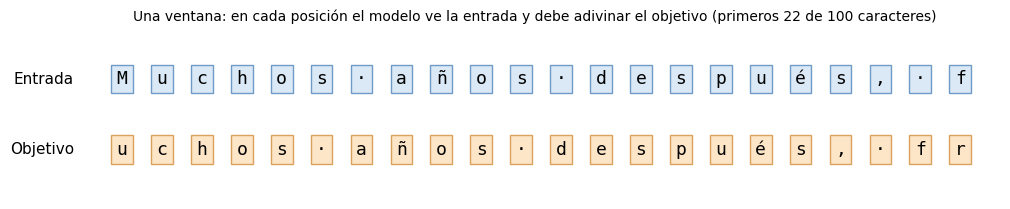

In [ ]:
sequence_length = LM_SEQ_LEN            # igual que en Shakespeare
paso = sequence_length           # ventanas sin solapamiento, como en el original

def ventanas(bloques):
    X, Y = [], []
    for b in bloques:
        for i in range(0, len(b) - sequence_length, paso):
            X.append(b[i : i + sequence_length])
            Y.append(b[i + 1 : i + sequence_length + 1])   # el objetivo es la entrada corrida un carácter
    return X, Y

x_train_txt, y_train_txt = ventanas(bloques_train)
x_val_txt,   y_val_txt   = ventanas(bloques_val)
print(f"Ventanas: train {len(x_train_txt):,} | val {len(x_val_txt):,} | largo de cada una: {sequence_length} caracteres")

def ver(c):
    return {" ": "·", "\n": "↵"}.get(c, c)

n = 22
fig, ax = plt.subplots(figsize=(12, 2.2))
for j in range(n):
    ax.text(j, 1, ver(x_train_txt[0][j]), ha="center", va="center", fontsize=13, family="monospace",
            bbox=dict(boxstyle="square", fc="#dbe9f6", ec="#6f9bc6"))
    ax.text(j, 0, ver(y_train_txt[0][j]), ha="center", va="center", fontsize=13, family="monospace",
            bbox=dict(boxstyle="square", fc="#fde6c8", ec="#d9a15b"))
ax.text(-1.2, 1, "Entrada", ha="right", va="center", fontsize=11)
ax.text(-1.2, 0, "Objetivo", ha="right", va="center", fontsize=11)
ax.set_xlim(-1.3, n); ax.set_ylim(-0.7, 1.7); ax.axis("off")
ax.set_title(f"Una ventana: en cada posición el modelo ve la entrada y debe adivinar el objetivo "
             f"(primeros {n} de {sequence_length} caracteres)", fontsize=10)
plt.savefig(FIGURAS / "lm_ventana.png", dpi=150, bbox_inches="tight")
plt.show()

## 1.3 Tokenización por carácter y referencias

Se construye el vocabulario de caracteres y se calculan dos referencias:
un modelo uniforme (azar) y un modelo unigrama (solo frecuencias).


Tamaño del vocabulario (86 caracteres + '' + [UNK]): 88
X_train: (7125, 100) | Y_train: (7125, 100) | X_val: (784, 100) | Y_val: (784, 100)
Comprobaciones OK: objetivo = entrada corrida, y los números vuelven al texto original
Primeros 12 números de la ventana 0: [39 12 13 23  5  7  2  3 35  5  7  2] -> 'Muchos años '


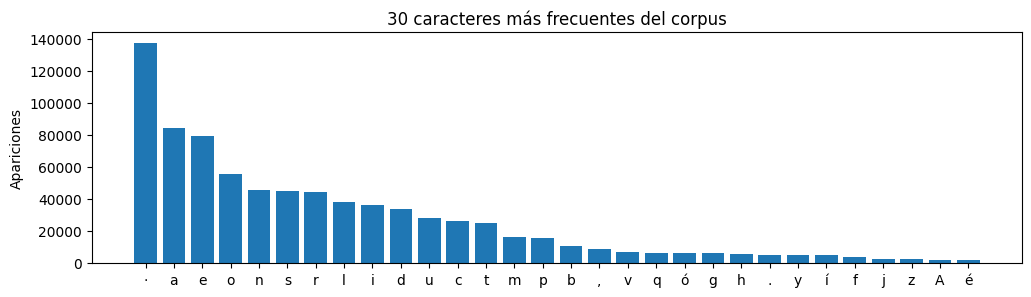

In [ ]:
import keras
from keras import layers
from collections import Counter

tokenizer = layers.TextVectorization(
    standardize=None,
    split="character",
    output_sequence_length=sequence_length,
)
tokenizer.adapt(np.array(bloques))        # vocabulario de todo el corpus: evita [UNK] en validación

vocabulary_size = tokenizer.vocabulary_size()
print("Tamaño del vocabulario (86 caracteres + '' + [UNK]):", vocabulary_size)

X_train = np.asarray(tokenizer(np.array(x_train_txt)))
Y_train = np.asarray(tokenizer(np.array(y_train_txt)))
X_val   = np.asarray(tokenizer(np.array(x_val_txt)))
Y_val   = np.asarray(tokenizer(np.array(y_val_txt)))
print("X_train:", X_train.shape, "| Y_train:", Y_train.shape, "| X_val:", X_val.shape, "| Y_val:", Y_val.shape)

id_to_char = dict(enumerate(tokenizer.get_vocabulary()))
char_to_id = {c: i for i, c in id_to_char.items()}

assert (X_train[:, 1:] == Y_train[:, :-1]).all(), "el objetivo debe ser la entrada corrida un carácter"
assert "".join(id_to_char[i] for i in X_train[0]) == x_train_txt[0], "la ida y vuelta falla"
print("Comprobaciones OK: objetivo = entrada corrida, y los números vuelven al texto original")
print("Primeros 12 números de la ventana 0:", X_train[0][:12], "->", repr("".join(id_to_char[i] for i in X_train[0][:12])))

frec = Counter(corpus).most_common(30)
fig, ax = plt.subplots(figsize=(12, 3))
ax.bar([ver(c) for c, _ in frec], [n for _, n in frec], color="tab:blue")
ax.set_title("30 caracteres más frecuentes del corpus")
ax.set_ylabel("Apariciones")
plt.savefig(FIGURAS / "lm_frecuencia_caracteres.png", dpi=150, bbox_inches="tight")
plt.show()

#### "modelo ingenuo" benchmark para comparar la perdida
1. Cuenta cuántas veces aparece cada carácter en el texto de entrenamiento. total es el número total de caracteres.
2. Une los bloques de validación en un solo texto de 80.000 caracteres. Sobre este texto se mide todo.
3. Uniforme: Es el modelo que adivina al azar: da la misma probabilidad, 1/88, a cada uno de los 88 caracteres. Su error por carácter es -log(1/88), que es igual a log(88) = 4,477.
4. Unigrama: Es el modelo que solo conoce la frecuencia de cada carácter. El "." ocupa ~17% del texto, así que siempre predice “.” con 17% de probabilidad, sin mirar qué había antes. Para cada carácter de validación toma la probabilidad que ese modelo le habría dado, calcula -log de ese valor y promedia. cnt.get(c, 1) evita un error: si un carácter nunca apareció en entrenamiento, como la W, su conteo sería 0 y log(0) da infinito, así que se le asigna 1.
5. Convierte cada pérdida en perplexity

In [ ]:
cnt = Counter("".join(bloques_train)); total = sum(cnt.values())
txt_val = "".join(bloques_val)

ce_uniforme = np.log(vocabulary_size)
ce_unigrama = -np.mean([np.log(cnt.get(c, 1) / total) for c in txt_val])
referencias = {"Uniforme": np.exp(ce_uniforme), "Unigrama": np.exp(ce_unigrama)}

print(f"Uniforme: pérdida {ce_uniforme:.3f} | perplexity {referencias['Uniforme']:.1f}")
print(f"Unigrama: pérdida {ce_unigrama:.3f} | perplexity {referencias['Unigrama']:.1f}")
print('Perplexity menor es mejor')

Uniforme: pérdida 4.477 | perplexity 88.0
Unigrama: pérdida 2.979 | perplexity 19.7
Perplexity menor es mejor


#### ¿Qué es la perplexity y cómo se interpreta aquí?

**perplexity** indica entre cuántos caracteres "duda" el modelo, en promedio, al predecir el siguiente. Se calcula a partir de la pérdida (log loss):

`perplexity = exp(pérdida)`

- **Menor es mejor.** Un valor de 1 significaría acertar siempre con total seguridad.
- **Referencias en este trabajo** (sobre el texto de validación):
  - **Uniforme: 88.** Es el azar, todos los caracteres igual de probables. Coincide con el tamaño del vocabulario.
  - **Unigrama: 19,7.** Solo conoce la frecuencia de cada carácter, sin mirar el contexto.
- **GRU:** cuanto más por debajo de 19,7 quede, más aprendió de cómo se encadenan los caracteres del libro, y no solo de su frecuencia.

Solo es comparable con modelos de caracteres evaluados sobre este mismo texto de validación. No mide la calidad del texto generado, sino qué tan bien predice el siguiente carácter en texto real.

## 1.4 Modelo GRU y entrenamiento

La arquitectura es la misma del notebook de referencia: embedding de 256,
GRU de 1024 unidades, dropout de 0.1 y una capa densa con softmax.


In [ ]:
keras.utils.set_random_seed(42)   # fija Python, NumPy y el backend (TensorFlow)

embedding_dim = 256     # 256 en Shakespeare
hidden_dim = 1024       # 1024 en Shakespeare
dropout = 0.1           # 0.1 en Shakespeare

inputs = layers.Input(shape=(sequence_length,), dtype="int", name="token_ids")
x = layers.Embedding(vocabulary_size, embedding_dim)(inputs)
x = layers.GRU(hidden_dim, return_sequences=True)(x)
x = layers.Dropout(dropout)(x)
outputs = layers.Dense(vocabulary_size, activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.summary(line_length=80)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ token_ids (InputLayer)            │ (None, 100)              │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ embedding (Embedding)             │ (None, 100, 256)         │        22,528 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ gru (GRU)                         │ (None, 100, 1024)        │     3,938,304 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dropout (Dropout)                 │ (None, 100, 1024)        │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense (Dense)                     │ (None, 100, 88)          │        90,200 │
└───────────────────────────────────┴──────────────────────────┴───────────────┘

 Total params: 4,051,032 (15.45 MB)

 Trainable params: 4,051,032 (15.45 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
EPOCAS_MAX = LM_EPOCAS   # tope; la parada anticipada puede cortar antes

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["sparse_categorical_accuracy"],
)

# Chequeo: sin entrenar, la pérdida debe estar cerca de la del azar
loss_inicial = model.evaluate(X_val, Y_val, verbose=0)[0]
print(f"Pérdida inicial en validación: {loss_inicial:.3f} | azar (uniforme): {np.log(vocabulary_size):.3f}")

parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=9, restore_best_weights=True)
historia = model.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    epochs=EPOCAS_MAX, batch_size=64,
    callbacks=[parada],
)

Pérdida inicial en validación: 4.477 | azar (uniforme): 4.477
Epoch 1/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 10s 62ms/step - loss: 2.5630 - sparse_categorical_accuracy: 0.2979 - val_loss: 2.0410 - val_sparse_categorical_accuracy: 0.3806
Epoch 2/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 63ms/step - loss: 1.9129 - sparse_categorical_accuracy: 0.4193 - val_loss: 1.7612 - val_sparse_categorical_accuracy: 0.4654
Epoch 3/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 66ms/step - loss: 1.6798 - sparse_categorical_accuracy: 0.4883 - val_loss: 1.5720 - val_sparse_categorical_accuracy: 0.5199
Epoch 4/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 10s 66ms/step - loss: 1.5217 - sparse_categorical_accuracy: 0.5354 - val_loss: 1.4459 - val_sparse_categorical_accuracy: 0.5578
Epoch 5/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 64ms/step - loss: 1.4094 - sparse_categorical_accuracy: 0.5677 - val_loss: 1.3609 - val_sparse_categorical_accuracy: 0.5839
Epoch 6/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 64ms/step - loss: 1.3249 - sparse_categorical_accuracy: 0.

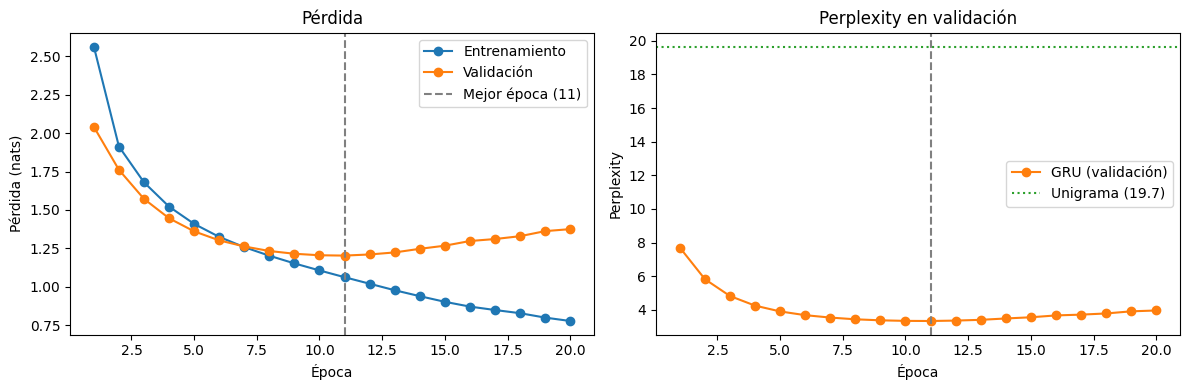

Mejor época: 11 | val_loss 1.203 | perplexity 3.3 | accuracy val 0.629


In [ ]:
h = historia.history
epocas = list(range(1, len(h["loss"]) + 1))
mejor = int(np.argmin(h["val_loss"])) + 1
perplexity_val = np.exp(h["val_loss"])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(epocas, h["loss"], marker="o", label="Entrenamiento")
ax[0].plot(epocas, h["val_loss"], marker="o", label="Validación")
ax[0].axvline(mejor, color="gray", linestyle="--", label=f"Mejor época ({mejor})")
ax[0].set_xlabel("Época"); ax[0].set_ylabel("Pérdida (nats)"); ax[0].set_title("Pérdida"); ax[0].legend()

ax[1].plot(epocas, perplexity_val, marker="o", color="tab:orange", label="GRU (validación)")
ax[1].axhline(referencias["Unigrama"], color="tab:green", linestyle=":", label=f"Unigrama ({referencias['Unigrama']:.1f})")
ax[1].axvline(mejor, color="gray", linestyle="--")
ax[1].set_xlabel("Época"); ax[1].set_ylabel("Perplexity"); ax[1].set_title("Perplexity en validación"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIGURAS / "lm_perdida_perplexity.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Mejor época: {mejor} | val_loss {h['val_loss'][mejor - 1]:.3f} | perplexity {perplexity_val[mejor - 1]:.1f} "
      f"| accuracy val {h['val_sparse_categorical_accuracy'][mejor - 1]:.3f}")

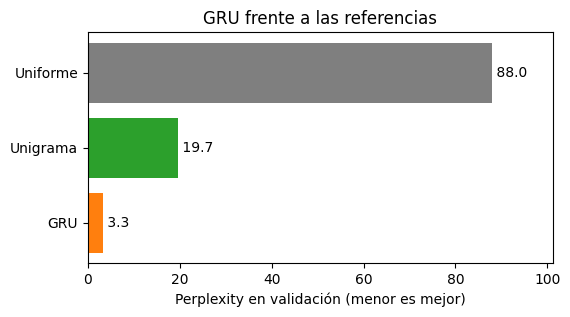

In [ ]:
referencias["GRU"] = float(perplexity_val[mejor - 1])

fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(list(referencias), list(referencias.values()), color=["tab:gray", "tab:green", "tab:orange"])
for i, v in enumerate(referencias.values()):
    ax.text(v, i, f" {v:.1f}", va="center")
ax.set_xlim(0, max(referencias.values()) * 1.15)
ax.set_xlabel("Perplexity en validación (menor es mejor)")
ax.set_title("GRU frente a las referencias")
ax.invert_yaxis()
plt.savefig(FIGURAS / "lm_perplexity_barras.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# Guardar métricas del modelo de lenguaje
h = historia.history
mejor_idx = int(np.argmin(h["val_loss"]))
lm_metrics = {
    "corpus_caracteres": int(len(corpus)),
    "corpus_palabras": int(len(corpus.split())),
    "parrafos": int(len(parrafos)),
    "vocabulario": int(vocabulary_size),
    "ventanas_train": int(len(X_train)),
    "ventanas_val": int(len(X_val)),
    "mejor_epoca": mejor_idx + 1,
    "val_loss": float(h["val_loss"][mejor_idx]),
    "perplexity": float(np.exp(h["val_loss"][mejor_idx])),
    "val_accuracy": float(h["val_sparse_categorical_accuracy"][mejor_idx]),
    "referencias": {k: float(v) for k, v in referencias.items()},
}
(RESULTADOS / "lm_metrics.json").write_text(json.dumps(lm_metrics, ensure_ascii=False, indent=2), encoding="utf-8")
(RESULTADOS / "lm_limpieza.json").write_text(json.dumps(reporte, ensure_ascii=False, indent=2), encoding="utf-8")
pd.DataFrame(h).to_csv(RESULTADOS / "lm_historial.csv", index=False)
print(json.dumps(lm_metrics, ensure_ascii=False, indent=2))


{
  "corpus_caracteres": 807072,
  "corpus_palabras": 137818,
  "parrafos": 730,
  "vocabulario": 88,
  "ventanas_train": 7125,
  "ventanas_val": 784,
  "mejor_epoca": 11,
  "val_loss": 1.2031337022781372,
  "perplexity": 3.3305374996662587,
  "val_accuracy": 0.6293367743492126,
  "referencias": {
    "Uniforme": 88.00000000000003,
    "Unigrama": 19.660030882098255,
    "GRU": 3.3305374996662587
  }
}


## 1.5 Generación de texto

Se compara la generación determinista (`argmax`) con el muestreo por
temperatura. Una temperatura baja produce texto más repetitivo y seguro;
una temperatura alta produce más variedad y más errores.


In [ ]:
# Modelo de generación
# Mismo modelo que el entrenado, pero recibe un solo carácter y la memoria del paso anterior,
# y devuelve las probabilidades del siguiente carácter y la memoria actualizada.
inputs = keras.Input(shape=(1,), dtype="int", name="token_ids")           # un carácter
input_state = keras.Input(shape=(hidden_dim,), name="state")              # memoria del GRU: resumen de lo leído hasta ahora

x = layers.Embedding(vocabulary_size, embedding_dim)(inputs)
# return_state devuelve la memoria actualizada; initial_state indica con qué memoria empezar
x, output_state = layers.GRU(hidden_dim, return_state=True)(
    x, initial_state=input_state
)
outputs = layers.Dense(vocabulary_size, activation="softmax")(x)          # una probabilidad por cada carácter del vocabulario
generation_model = keras.Model(
    inputs=(inputs, input_state),
    outputs=(outputs, output_state),
)

# El modelo nuevo parte con pesos al azar; esta línea le copia los pesos entrenados
generation_model.set_weights(model.get_weights())

In [ ]:
# Vocabulario y prompt
# El modelo trabaja con números: estos diccionarios permiten pasar de carácter a número y de número a carácter
tokens = tokenizer.get_vocabulary()
token_ids = range(vocabulary_size)
char_to_id = dict(zip(tokens, token_ids))
id_to_char = dict(zip(token_ids, tokens))

prompt = "Ursula"     # texto inicial; solo caracteres que existan en el libro

In [ ]:
# Lectura del prompt
# El modelo lee el prompt carácter por carácter para cargar su memoria con ese contexto.
# Al terminar, predictions contiene las probabilidades del primer carácter nuevo.
input_ids = [char_to_id[c] for c in prompt]
state = keras.ops.zeros(shape=(1, hidden_dim))                            # memoria vacía al empezar
for token_id in input_ids:
    inputs = keras.ops.expand_dims([token_id], axis=0)                    # un carácter, con forma (ejemplos, pasos)
    predictions, state = generation_model.predict((inputs, state), verbose=0)   # probabilidades y memoria actualizada

# Se guarda este punto para volver a él más adelante
predictions_del_prompt, state_del_prompt = predictions, state
print(f"predictions tiene forma {predictions.shape}: una probabilidad por cada uno de los {vocabulary_size} caracteres")

predictions tiene forma (1, 88): una probabilidad por cada uno de los 88 caracteres


In [ ]:
# Generación con argmax (método original)
# En cada paso se elige el carácter más probable y se usa como entrada del paso siguiente.
# Al no haber azar, el texto tiende a repetirse.
generated_ids = []
max_length = 80 if MODO_PRUEBA else 250
for i in range(max_length):
    next_char = int(np.argmax(predictions, axis=-1)[0])                   # el carácter más probable
    generated_ids.append(next_char)
    inputs = keras.ops.expand_dims([next_char], axis=0)                   # el carácter elegido es la entrada del paso siguiente
    predictions, state = generation_model.predict((inputs, state), verbose=0)

resultado_argmax = "".join([id_to_char[token_id] for token_id in generated_ids])
print(prompt + resultado_argmax)

Ursula de la muerte de Aureliano Segundo se había conseguido el escurridizo de la muerte de Aureliano Segundo se había conseguido el escurridizo de la muerte de Aureliano Segundo se había conseguido el escurridizo de la muerte de Aureliano Segundo se había


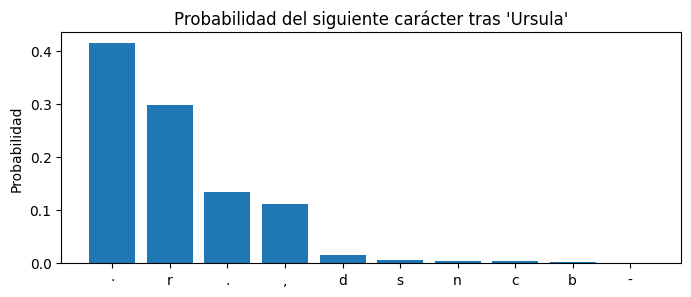

Las probabilidades de los 88 caracteres suman 1.00
argmax elige siempre '·' (probabilidad 0.41) e ignora el resto


In [ ]:
# Distribución de probabilidad tras el prompt
# El modelo no entrega un solo carácter sino una probabilidad para cada uno; argmax usa únicamente la más alta.
probs_prompt = np.array(predictions_del_prompt[0])
top = np.argsort(probs_prompt)[::-1][:10]

plt.figure(figsize=(8, 3))
plt.bar([ver(id_to_char[i]) for i in top], probs_prompt[top], color="tab:blue")
plt.title(f"Probabilidad del siguiente carácter tras {prompt!r}")
plt.ylabel("Probabilidad")
plt.savefig(FIGURAS / "lm_distribucion_prompt.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Las probabilidades de los {vocabulary_size} caracteres suman {probs_prompt.sum():.2f}")
letra = str(ver(id_to_char[top[0]]))
print(f"argmax elige siempre {letra!r} (probabilidad {probs_prompt[top[0]]:.2f}) e ignora el resto")

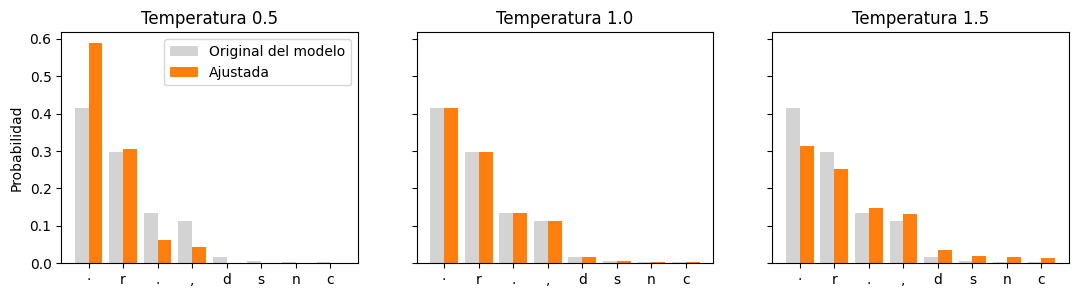

In [ ]:
# Ajuste por temperatura
# La temperatura modifica la distribución antes de elegir el carácter:
#   menor que 1: concentra la probabilidad en los favoritos (texto más seguro y más repetitivo)
#   igual a 1: deja la distribución como está
#   mayor que 1: la reparte de forma más pareja (texto más variado y con más errores)
def ajustar_temperatura(predictions, temperatura):
    probs = np.array(predictions[0], dtype="float64")
    logits = np.log(probs + 1e-9) / temperatura     # dividir entre la temperatura es lo que concentra o aplana
    logits[:2] = -np.inf                            # los dos primeros ids son relleno y desconocido, no caracteres del libro
    probs = np.exp(logits - logits.max())           # volver de logaritmo a probabilidad
    return probs / probs.sum()                      # renormalizar para que sumen uno

# Gráfica: gris es la distribución original y naranja la ajustada
orden = np.argsort(probs_prompt)[::-1][:8]
pos = np.arange(len(orden))
fig, axes = plt.subplots(1, 3, figsize=(13, 3), sharey=True)
for ax, T in zip(axes, (0.5, 1.0, 1.5)):
    ajustadas = ajustar_temperatura(predictions_del_prompt, T)
    ax.bar(pos - 0.2, probs_prompt[orden], width=0.4, color="lightgray", label="Original del modelo")
    ax.bar(pos + 0.2, ajustadas[orden], width=0.4, color="tab:orange", label="Ajustada")
    ax.set_xticks(pos)
    ax.set_xticklabels([ver(id_to_char[i]) for i in orden])
    ax.set_title(f"Temperatura {T}")
axes[0].set_ylabel("Probabilidad")
axes[0].legend()
plt.savefig(FIGURAS / "lm_temperaturas.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# Generación con temperatura
# Igual que la generación con argmax, pero el carácter se sortea según las probabilidades ajustadas.
# Se repite con varias temperaturas, partiendo siempre del mismo punto.
max_length = 80 if MODO_PRUEBA else 250
resultados_temperatura = {}

for temperatura in (0.25, 0.5, 1.0, 1.25, 1.5):
    rng = np.random.default_rng(42)                                       # semilla fija: cada temperatura da siempre el mismo texto
    predictions, state = predictions_del_prompt, state_del_prompt         # volver al punto justo después del prompt
    generated_ids = []
    for i in range(max_length):
        probs = ajustar_temperatura(predictions, temperatura)             # distribución ajustada
        next_char = int(rng.choice(vocabulary_size, p=probs))             # sorteo: un carácter con 20% de probabilidad sale cerca del 20% de las veces
        generated_ids.append(next_char)
        inputs = keras.ops.expand_dims([next_char], axis=0)
        predictions, state = generation_model.predict((inputs, state), verbose=0)
    output = "".join([id_to_char[token_id] for token_id in generated_ids])
    resultados_temperatura[temperatura] = prompt + output
    print(f"===== Temperatura {temperatura} =====")
    print(prompt + output + "\n")

===== Temperatura 0.25 =====
Ursula de los comprobados que los comprendió que la muerte de Melquíades, y con la muerte de Aureliano Segundo se atrevió a la casa sin embargo, el propio de los trenes en la muerte de Aureliano Segundo y Amaranta estaban en el cuarto de Melquíades. Aureli

===== Temperatura 0.5 =====
Ursular con la tienda de Catarino a los colores, que se enteró de por los ojos a la tienda de Catarino, aprendiera la muerte de la casa al coronel Aureliano Buendía. El oficial esperaban, Aureliano se lo confió a la casa con la muerte de José Arcadio Buend

===== Temperatura 1.0 =====
Ursula, y expuesto por el miémbo espejo en la comportación porteneral que era pasaran las armas de un calgonofico donde sus mirnas de su vida fue la visita buen medilagional. Había achivutado sobre el amisto. A las tierras ni siquiera en hojerla muerto. En

===== Temperatura 1.25 =====
Ursula, y expuesto por el poque tanto, con la ciprignada abimpedeada por la segunda pistona pesas de que Furnín,

In [ ]:
# Guardar los textos generados para el informe
lineas = ["PROMPT: " + prompt, "", "[ARGMAX]", resultado_argmax, ""]
for temperatura, texto in resultados_temperatura.items():
    lineas.extend([f"[TEMPERATURA {temperatura}]", texto, ""])
(RESULTADOS / "lm_generaciones.txt").write_text("\n".join(lineas), encoding="utf-8")
print("Generaciones guardadas en", RESULTADOS / "lm_generaciones.txt")


Generaciones guardadas en /content/resultados_taller/lm_generaciones.txt


# Parte 2. Traducción español → inglés

Se reutiliza la arquitectura del notebook del profesor: encoder BiGRU y
decoder GRU. Para no sobrecomplicar el taller, **no se alinean oraciones**:
cada fila del CSV es un par de traducción y los textos largos se truncan a
50 palabras. Es una simplificación documentada en el informe.


## 2.1 Carga del dataset

El CSV tiene las columnas:

- `statement_es_es`: texto en español (entrada).
- `statement`: texto en inglés (salida esperada).
- `status`: categoría temática; se usa solo para analizar resultados.


In [ ]:
df = pd.read_csv(RUTA_DATASET)
print("Filas:", len(df))
print("Columnas:", list(df.columns))
print(df.head(3).to_string(max_colwidth=80))


Filas: 53043
Columnas: ['Unnamed: 0', 'statement', 'status', 'statement_es_es']
   Unnamed: 0                                                                       statement   status                                                                  statement_es_es
0           0                                                                      oh my gosh  Anxiety                                                                      ay Dios mío
1           1                trouble sleeping, confused mind, restless heart. All out of tune  Anxiety       problemas para dormir, mente confundida, corazón inquieto. Todo desafinada
2           2  All wrong, back off dear, forward doubt. Stay in a restless and restless place  Anxiety  todo mal, aléjate cariño, duda hacia adelante. Quédate en un lugar inquieto ...


## 2.2 Limpieza y construcción de pares

Se pasa todo a minúsculas, se quitan URLs, HTML y puntuación, y se trunca.
La referencia inglesa se guarda sin etiquetas; el objetivo del modelo lleva
`[start]` y `[end]`.


In [ ]:
def normalizar(texto):
    """Minúsculas, sin URLs/HTML y sin puntuación; conserva letras y números."""
    texto = unicodedata.normalize("NFC", str(texto)).lower()
    texto = re.sub(r"https?://\S+|www\.\S+", " ", texto)
    texto = re.sub(r"<[^>]+>", " ", texto)
    texto = re.sub(r"[^a-záéíóúüñ0-9 ]+", " ", texto)
    return re.sub(r"\s+", " ", texto).strip()


def preparar_par(es, en, max_len=MT_MAX_LEN):
    """Devuelve (español, referencia inglesa, inglés con etiquetas) o None."""
    es = normalizar(es)
    en = normalizar(en)
    es_palabras = es.split()[:max_len]
    en_palabras = en.split()[:max_len - 2]  # deja espacio para [start] y [end]
    if len(es_palabras) < 2 or len(en_palabras) < 2:
        return None
    es_txt = " ".join(es_palabras)
    en_ref = " ".join(en_palabras)
    if es_txt == en_ref:
        return None
    en_tgt = f"[start] {en_ref} [end]"
    return es_txt, en_ref, en_tgt


pares = []
for _, fila in df.iterrows():
    par = preparar_par(fila["statement_es_es"], fila["statement"])
    if par is not None:
        pares.append({"status": fila["status"], "es": par[0], "en_ref": par[1], "en_tgt": par[2]})

# Quitar duplicados exactos
vistos, unicos = set(), []
for p in pares:
    clave = (p["es"], p["en_ref"])
    if clave not in vistos:
        vistos.add(clave)
        unicos.append(p)
pares = unicos

if MODO_PRUEBA and len(pares) > MT_MAX_PARES_PRUEBA:
    rng = np.random.default_rng(SEED)
    elegidos = rng.choice(len(pares), MT_MAX_PARES_PRUEBA, replace=False)
    pares = [pares[i] for i in elegidos]

print(f"Pares utilizables: {len(pares):,}")
print(pd.DataFrame(pares).head(5).to_string(max_colwidth=100))


Pares utilizables: 51,252
    status                                                                                     es                                                                       en_ref                                                                                     en_tgt
0  Anxiety                                                                            ay dios mío                                                                   oh my gosh                                                                   [start] oh my gosh [end]
1  Anxiety                problemas para dormir mente confundida corazón inquieto todo desafinada                trouble sleeping confused mind restless heart all out of tune                [start] trouble sleeping confused mind restless heart all out of tune [end]
2  Anxiety  todo mal aléjate cariño duda hacia adelante quédate en un lugar inquieto y angustiado  all wrong back off dear forward doubt stay in a restless and restless place  

{
  "filas_csv": 53043,
  "pares_utilizables": 51252,
  "palabras_es_media": 35.17907593849996,
  "palabras_en_media": 34.95920159213299,
  "max_len": 50,
  "status": {
    "Depression": 15308,
    "Normal": 15085,
    "Suicidal": 10615,
    "Anxiety": 3821,
    "Bipolar": 2776,
    "Stress": 2573,
    "Personality disorder": 1074
  }
}


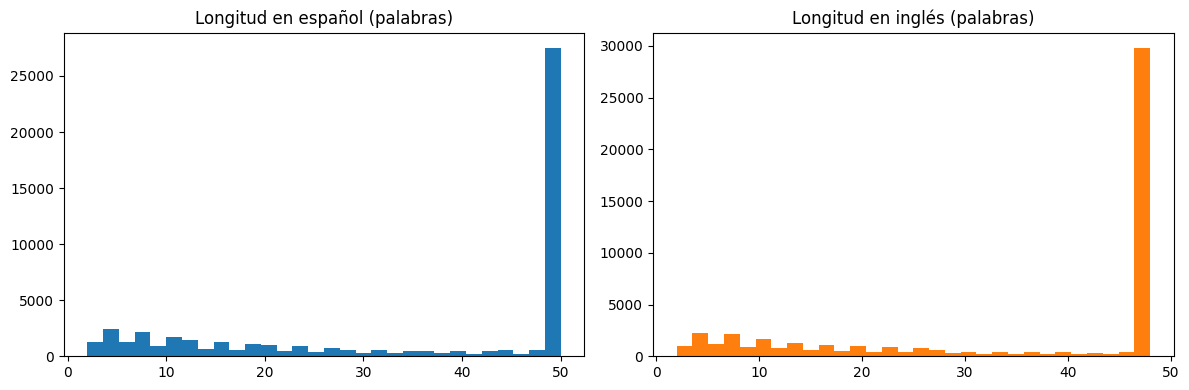

In [ ]:
df_pares = pd.DataFrame(pares)
df_pares["len_es"] = df_pares["es"].str.split().str.len()
df_pares["len_en"] = df_pares["en_ref"].str.split().str.len()

stats = {
    "filas_csv": int(len(df)),
    "pares_utilizables": int(len(df_pares)),
    "palabras_es_media": float(df_pares["len_es"].mean()),
    "palabras_en_media": float(df_pares["len_en"].mean()),
    "max_len": MT_MAX_LEN,
    "status": df_pares["status"].value_counts().to_dict(),
}
(RESULTADOS / "data_stats.json").write_text(json.dumps(stats, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(stats, ensure_ascii=False, indent=2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df_pares["len_es"], bins=30, color="tab:blue")
axes[0].set_title("Longitud en español (palabras)")
axes[1].hist(df_pares["len_en"], bins=30, color="tab:orange")
axes[1].set_title("Longitud en inglés (palabras)")
plt.tight_layout()
plt.savefig(FIGURAS / "mt_longitudes.png", dpi=150, bbox_inches="tight")
plt.show()


## 2.3 División train / validation / test

Se usa una semilla fija para que la división sea reproducible.


In [ ]:
rng = np.random.default_rng(SEED)
indices = rng.permutation(len(pares))
n = len(indices)
n_val = int(0.10 * n)
n_test = int(0.10 * n)
n_train = n - n_val - n_test

train = [pares[i] for i in indices[:n_train]]
val = [pares[i] for i in indices[n_train:n_train + n_val]]
test = [pares[i] for i in indices[n_train + n_val:]]
print(f"Train: {len(train):,} | Val: {len(val):,} | Test: {len(test):,}")


Train: 41,002 | Val: 5,125 | Test: 5,125


## 2.4 Tokenizadores

Se usan tokenizadores por palabras con vocabulario de 20.000 tokens.
La entrada y la salida se recortan o rellenan a 50 posiciones.


In [ ]:
source_vectorizer = layers.TextVectorization(
    max_tokens=MT_VOCAB,
    output_mode="int",
    output_sequence_length=MT_MAX_LEN,
    standardize=None,
)
target_vectorizer = layers.TextVectorization(
    max_tokens=MT_VOCAB,
    output_mode="int",
    output_sequence_length=MT_MAX_LEN,
    standardize=None,
)
source_vectorizer.adapt([p["es"] for p in train])
target_vectorizer.adapt([p["en_tgt"] for p in train])

vocab_es = source_vectorizer.get_vocabulary()
vocab_en = target_vectorizer.get_vocabulary()
print("Vocabulario español:", len(vocab_es))
print("Vocabulario inglés:", len(vocab_en))


Vocabulario español: 20000
Vocabulario inglés: 20000


In [ ]:
def vectorizar(pares):
    """Convierte pares en arreglos: entrada, decoder_input, decoder_output y máscara."""
    X = np.asarray(source_vectorizer([p["es"] for p in pares]), dtype="int32")
    Y = np.asarray(target_vectorizer([p["en_tgt"] for p in pares]), dtype="int32")
    return X, Y[:, :-1], Y[:, 1:], (Y[:, 1:] != 0).astype("float32")

X_tr, dec_in_tr, dec_out_tr, w_tr = vectorizar(train)
X_va, dec_in_va, dec_out_va, w_va = vectorizar(val)
X_te = np.asarray(source_vectorizer([p["es"] for p in test]), dtype="int32")

print("X_train:", X_tr.shape)
print("decoder_input:", dec_in_tr.shape)
print("decoder_output:", dec_out_tr.shape)
print("X_test:", X_te.shape)


X_train: (41002, 50)
decoder_input: (41002, 49)
decoder_output: (41002, 49)
X_test: (5125, 50)


## 2.5 Modelo seq2seq

El encoder lee el español y resume la secuencia en un vector. El decoder
recibe la traducción desplazada (con `[start]`) y predice la siguiente palabra.


In [ ]:
keras.utils.set_random_seed(SEED)
embed_dim = 256
hidden_dim = 1024

# Encoder: español -> vector de contexto
source = keras.Input(shape=(None,), dtype="int32", name="es")
x = layers.Embedding(source_vectorizer.vocabulary_size(), embed_dim)(source)
encoder = layers.Bidirectional(layers.GRU(hidden_dim), merge_mode="sum")(x)

# Decoder: inglés desplazado, inicializado con el contexto
target = keras.Input(shape=(None,), dtype="int32", name="en")
x = layers.Embedding(target_vectorizer.vocabulary_size(), embed_dim)(target)
x = layers.GRU(hidden_dim, return_sequences=True)(x, initial_state=encoder)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(target_vectorizer.vocabulary_size(), activation="softmax")(x)

modelo = keras.Model([source, target], outputs, name="seq2seq_es_en")
modelo.summary(line_length=90)


Model: "seq2seq_es_en"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)             ┃ Output Shape         ┃      Param # ┃ Connected to          ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━┩
│ es (InputLayer)          │ (None, None)         │            0 │ -                     │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ en (InputLayer)          │ (None, None)         │            0 │ -                     │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ embedding_2 (Embedding)  │ (None, None, 256)    │    5,120,000 │ es[0][0]              │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ embedding_3 (Embedding)  │ (None, None, 256)    │    5,120,000 │ en[0][0]              │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ bidirectional            │ (None, 1024)         │    7,876,608 │ embedding_2[0][0]     │
│ (Bidirectional)          │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ gru_3 (GRU)              │ (None, None, 1024)   │    3,938,304 │ embedding_3[0][0],    │
│                          │                      │              │ bidirectional[0][0]   │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ dropout_1 (Dropout)      │ (None, None, 1024)   │            0 │ gru_3[0][0]           │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ dense_2 (Dense)          │ (None, None, 20000)  │   20,500,000 │ dropout_1[0][0]       │
└──────────────────────────┴──────────────────────┴──────────────┴───────────────────────┘

 Total params: 42,554,912 (162.33 MB)

 Trainable params: 42,554,912 (162.33 MB)

 Non-trainable params: 0 (0.00 B)

## 2.6 Entrenamiento

Se usa entropía cruzada con máscara para ignorar el padding. La parada
anticipada evita seguir entrenando cuando la validación deja de mejorar.


In [ ]:
modelo.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    weighted_metrics=["accuracy"],
)

# EarlyStopping guarda en memoria los mejores pesos; no se guarda el modelo
# para que el ZIP de resultados sea liviano.
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
]

historia_mt = modelo.fit(
    {"es": X_tr, "en": dec_in_tr},
    dec_out_tr,
    sample_weight=w_tr,
    validation_data=({"es": X_va, "en": dec_in_va}, dec_out_va, w_va),
    batch_size=MT_BATCH,
    epochs=MT_EPOCAS,
    callbacks=callbacks,
    verbose=1,
)


Epoch 1/10
641/641 ━━━━━━━━━━━━━━━━━━━━ 182s 277ms/step - accuracy: 0.1363 - loss: 4.2120 - val_accuracy: 0.1979 - val_loss: 3.6120
Epoch 2/10
641/641 ━━━━━━━━━━━━━━━━━━━━ 200s 277ms/step - accuracy: 0.2072 - loss: 3.5650 - val_accuracy: 0.2330 - val_loss: 3.3235
Epoch 3/10
641/641 ━━━━━━━━━━━━━━━━━━━━ 177s 277ms/step - accuracy: 0.2394 - loss: 3.2942 - val_accuracy: 0.2661 - val_loss: 3.1328
Epoch 4/10
641/641 ━━━━━━━━━━━━━━━━━━━━ 202s 277ms/step - accuracy: 0.2660 - loss: 3.0735 - val_accuracy: 0.2840 - val_loss: 3.0094
Epoch 5/10
641/641 ━━━━━━━━━━━━━━━━━━━━ 187s 292ms/step - accuracy: 0.2877 - loss: 2.8816 - val_accuracy: 0.2986 - val_loss: 2.9251
Epoch 6/10
641/641 ━━━━━━━━━━━━━━━━━━━━ 177s 277ms/step - accuracy: 0.3060 - loss: 2.7182 - val_accuracy: 0.3079 - val_loss: 2.8792
Epoch 7/10
641/641 ━━━━━━━━━━━━━━━━━━━━ 177s 276ms/step - accuracy: 0.3244 - loss: 2.5743 - val_accuracy: 0.3122 - val_loss: 2.8542
Epoch 8/10
641/641 ━━━━━━━━━━━━━━━━━━━━ 187s 292ms/step - accuracy: 0.3430 -

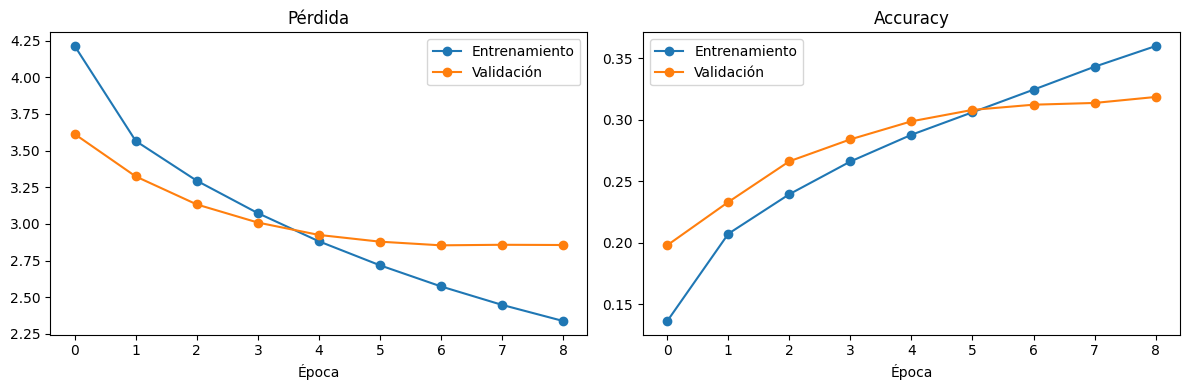

Historial guardado.


In [ ]:
hist = historia_mt.history
clave_acc = "accuracy" if "accuracy" in hist else "sparse_categorical_accuracy"

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, clave, titulo in [
    (axes[0], "loss", "Pérdida"),
    (axes[1], clave_acc, "Accuracy"),
]:
    ax.plot(hist[clave], marker="o", label="Entrenamiento")
    ax.plot(hist[f"val_{clave}"], marker="o", label="Validación")
    ax.set_title(titulo)
    ax.set_xlabel("Época")
    ax.legend()

plt.tight_layout()
plt.savefig(FIGURAS / "mt_entrenamiento.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame(hist).to_csv(RESULTADOS / "mt_historial.csv", index=False)
print("Historial guardado.")


## 2.7 Traducción por lotes

Se implementa decodificación greedy por lotes. Es equivalente a generar
palabra por palabra, pero mucho más rápido para evaluar todo el test.


In [ ]:
vocab_en = target_vectorizer.get_vocabulary()
id_a_token = {i: t for i, t in enumerate(vocab_en)}
start_id = vocab_en.index("[start]")
end_id = vocab_en.index("[end]")
unk_id = vocab_en.index("[UNK]") if "[UNK]" in vocab_en else 1


def traducir_lote(frases, batch_size=256):
    """Decodificación greedy por lotes."""
    resultados = []
    for inicio in range(0, len(frases), batch_size):
        lote = frases[inicio:inicio + batch_size]
        src = np.asarray(source_vectorizer(lote), dtype="int32")
        dec = np.zeros((len(lote), MT_MAX_LEN - 1), dtype="int32")
        dec[:, 0] = start_id
        terminado = np.zeros(len(lote), dtype=bool)
        salidas = [[] for _ in lote]

        for paso in range(MT_MAX_LEN - 2):
            pred = modelo.predict({"es": src, "en": dec}, verbose=0, batch_size=len(lote))
            siguientes = np.argmax(pred[:, paso, :], axis=-1)
            for i, token in enumerate(siguientes):
                if terminado[i]:
                    continue
                if token == end_id:
                    terminado[i] = True
                elif token not in (0, unk_id, start_id):
                    salidas[i].append(int(token))
                    if paso + 1 < dec.shape[1]:
                        dec[i, paso + 1] = token
            if terminado.all():
                break

        resultados.extend(" ".join(id_a_token[t] for t in tokens) for tokens in salidas)
    return resultados


# Prueba visual con cinco ejemplos
for frase, ref in zip([p["es"] for p in test[:5]], [p["en_ref"] for p in test[:5]]):
    print("ES:", frase)
    print("EN ref:", ref)
    print("EN hip:", traducir_lote([frase])[0])
    print()


ES: remedio para la depresión pequeño paso gran impacto http t co kebtd od depresión psicología humana remedio
EN ref: depression remedy little step big impact http t co kebtd od depression humanpsychology remedy
EN hip: introduction to the depression of depression but it s not clear to the risk of depression

ES: te pillaron usando drogas
EN ref: did she catch you using drugs
EN hip: you did you have to take them

ES: cada día me siento más y más sola tengo gente a mi alrededor sí sí pero no hay alguien que sea mi persona si lo entiendo es tan difícil pedirle a alguien que será tu apoyo consuelo mejor amigo alguien que me mantenga adelante me ayude a salir de los
EN ref: everyday i get more and more lonelier i have people around yes yes but not someone who is my person if that makes sense is it so hard to ask for someone that will be your support comfort best friend someone who keeps me going helps me get
EN hip: every day i have to be and i feel like my soul is not worth it but i can

## 2.8 Métricas: BLEU, ROUGE y F1

- **BLEU:** precisión de n-gramas con penalización por brevedad.
- **ROUGE-1/2/L:** solapamiento de unigramas, bigramas y subsecuencia más larga.
- **F1:** precisión y recall por solapamiento de tokens (macro y micro).

Todas las métricas se calculan sobre el texto normalizado (minúsculas, sin puntuación).


In [ ]:
from sacrebleu import corpus_bleu, corpus_chrf
from rouge_score import rouge_scorer


def f1_tokens(hipotesis, referencia):
    """Precisión, recall y F1 por solapamiento de tokens."""
    h, r = hipotesis.split(), referencia.split()
    if not h or not r:
        return 0.0, 0.0, 0.0
    comunes = sum((Counter(h) & Counter(r)).values())
    precision = comunes / len(h)
    recall = comunes / len(r)
    f1 = 0.0 if precision + recall == 0 else 2 * precision * recall / (precision + recall)
    return precision, recall, f1


def evaluar(hipotesis, referencias):
    """Calcula BLEU, chrF, ROUGE y F1 para un conjunto de pares."""
    bleu = corpus_bleu(hipotesis, [referencias], tokenize="13a")
    chrf = corpus_chrf(hipotesis, [referencias])
    scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)

    rouge = {"rouge1": [], "rouge2": [], "rougeL": []}
    f1s, ps, rs, bleu_frases = [], [], [], []
    for h, r in zip(hipotesis, referencias):
        scores = scorer.score(r, h)
        for clave in rouge:
            rouge[clave].append(scores[clave].fmeasure)
        p, rec, f1 = f1_tokens(h, r)
        ps.append(p); rs.append(rec); f1s.append(f1)
        bleu_frases.append(corpus_bleu([h], [[r]], tokenize="13a").score)

    comunes = sum(sum((Counter(h.split()) & Counter(r.split())).values())
                  for h, r in zip(hipotesis, referencias))
    total_h = sum(len(h.split()) for h in hipotesis)
    total_r = sum(len(r.split()) for r in referencias)
    micro_p = comunes / total_h if total_h else 0.0
    micro_r = comunes / total_r if total_r else 0.0
    micro_f1 = 0.0 if micro_p + micro_r == 0 else 2 * micro_p * micro_r / (micro_p + micro_r)

    return {
        "n": len(hipotesis),
        "bleu": float(bleu.score),
        "bleu_frase_media": float(np.mean(bleu_frases)),
        "chrf": float(chrf.score),
        "rouge1_f1": float(np.mean(rouge["rouge1"])),
        "rouge2_f1": float(np.mean(rouge["rouge2"])),
        "rougeL_f1": float(np.mean(rouge["rougeL"])),
        "f1_macro": float(np.mean(f1s)),
        "f1_micro": float(micro_f1),
        "precision_macro": float(np.mean(ps)),
        "recall_macro": float(np.mean(rs)),
        "precision_micro": float(micro_p),
        "recall_micro": float(micro_r),
    }


In [ ]:
test_es = [p["es"] for p in test]
test_ref = [p["en_ref"] for p in test]
test_status = [p["status"] for p in test]

hipotesis = traducir_lote(test_es, batch_size=256)
metricas = evaluar(hipotesis, test_ref)
metricas.update({
    "modelo": "BiGRU + GRU seq2seq",
    "max_len": MT_MAX_LEN,
    "vocab_es": len(vocab_es),
    "vocab_en": len(vocab_en),
})

(RESULTADOS / "mt_metrics.json").write_text(
    json.dumps(metricas, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(json.dumps(metricas, ensure_ascii=False, indent=2))


{
  "n": 5125,
  "bleu": 6.438577296524428,
  "bleu_frase_media": 7.623822450200498,
  "chrf": 26.338917543187502,
  "rouge1_f1": 0.3531729340060539,
  "rouge2_f1": 0.10939288046978032,
  "rougeL_f1": 0.2800738080151305,
  "f1_macro": 0.3454698180846195,
  "f1_micro": 0.3516810813906867,
  "precision_macro": 0.36429293126601486,
  "recall_macro": 0.3390465019035594,
  "precision_micro": 0.35952477149097384,
  "recall_micro": 0.34417233280455606,
  "modelo": "BiGRU + GRU seq2seq",
  "max_len": 50,
  "vocab_es": 20000,
  "vocab_en": 20000
}


In [ ]:
scorer_l = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)
df_pred = pd.DataFrame({
    "status": test_status,
    "es": test_es,
    "referencia": test_ref,
    "hipotesis": hipotesis,
})
df_pred["bleu_frase"] = [corpus_bleu([h], [[r]], tokenize="13a").score
                         for h, r in zip(hipotesis, test_ref)]
df_pred["f1_frase"] = [f1_tokens(h, r)[2] for h, r in zip(hipotesis, test_ref)]
df_pred["rougeL_frase"] = [scorer_l.score(r, h)["rougeL"].fmeasure
                           for h, r in zip(hipotesis, test_ref)]
df_pred.to_csv(RESULTADOS / "predicciones_test.csv", index=False, encoding="utf-8-sig")
print(df_pred.head(10).to_string(max_colwidth=100))


       status                                                                                                   es                                                                                           referencia                                                                                            hipotesis  bleu_frase  f1_frase  rougeL_frase
0  Depression  remedio para la depresión pequeño paso gran impacto http t co kebtd od depresión psicología huma...        depression remedy little step big impact http t co kebtd od depression humanpsychology remedy            introduction to the depression of depression but it s not clear to the risk of depression    2.908318  0.133333      0.133333
1      Normal                                                                            te pillaron usando drogas                                                                        did she catch you using drugs                                                                        you did

## 2.9 Ejemplos y análisis de errores

Se guardan ejemplos para el informe y los 20 casos con peor F1. En el informe
solo se mostrarán ejemplos neutrales y anonimizados por el contenido sensible
del dataset.


In [ ]:
# Ejemplos preferentemente neutrales para el informe
filtro = df_pred["status"].isin(["Normal", "Stress", "Anxiety"])
filtro &= df_pred["referencia"].str.len() > 20
filtro &= ~df_pred["es"].str.contains(r"\d", regex=True)
candidatos = df_pred[filtro]
if len(candidatos) == 0:
    candidatos = df_pred
ejemplos = candidatos.sample(min(10, len(candidatos)), random_state=SEED)
ejemplos.to_csv(RESULTADOS / "ejemplos.csv", index=False, encoding="utf-8-sig")
print(ejemplos[["es", "referencia", "hipotesis", "bleu_frase", "f1_frase"]].to_string(max_colwidth=100))

errores = df_pred[df_pred["status"] != "Suicidal"].sort_values(["f1_frase", "bleu_frase"]).head(20)
errores.to_csv(RESULTADOS / "errores.csv", index=False, encoding="utf-8-sig")
print("\nPeores 20 casos (sin la categoría Suicidal):")
print(errores[["status", "es", "referencia", "hipotesis", "f1_frase"]].to_string(max_colwidth=90))


                                                                                                       es                                                                                           referencia                                                                                            hipotesis  bleu_frase  f1_frase
1344  no es de extrañar que me regañen por las malas notas me llamen un tipo vago e inútil porque no t...  no wonder i get scolded for bad grades called a lazy worthless piece of fuck because i am too la...  it s not going to be happy with me i m going to be happy and i m not going to be happy or anythi...    1.352470  0.208333
1750                 rezando por su nuevo trabajo y carrera alabando a dios por conseguir un nuevo empleo                                              prays for his new job career praise god i got a new job                                      tomorrow morning and work in a new job tomorrow is a huge point   11.498760  0.230769
1745  incl

## 2.10 Métricas por categoría

La columna `status` no se usa para entrenar, pero permite ver si el modelo
traduce mejor unas categorías que otras.


              status    n     bleu  rougeL_f1  f1_macro  f1_micro
            Suicidal 1048 7.753870   0.290689  0.375382  0.376422
          Depression 1545 6.824473   0.276289  0.360073  0.361787
             Anxiety  363 5.282884   0.273030  0.345662  0.336219
              Stress  245 5.193122   0.249283  0.336647  0.339435
             Bipolar  266 4.511623   0.239603  0.326381  0.328256
Personality disorder  110 4.621545   0.243154  0.325830  0.334198
              Normal 1548 5.350539   0.292768  0.316672  0.306718


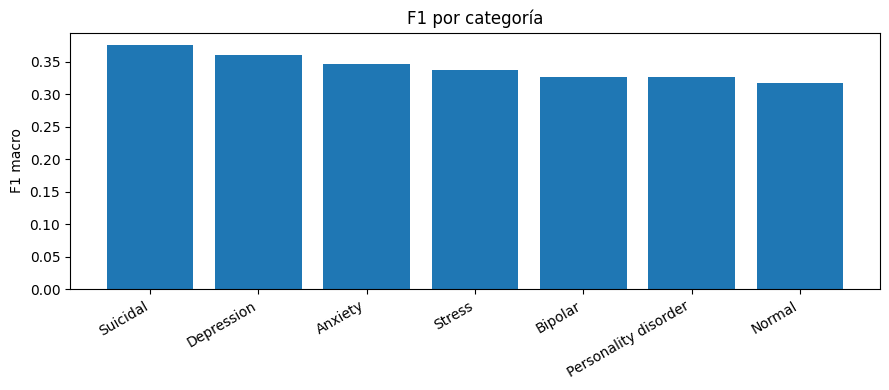

In [ ]:
umbral = 5 if MODO_PRUEBA else 20
filas = []
for status, grupo in df_pred.groupby("status"):
    if len(grupo) < umbral:
        continue
    m = evaluar(grupo["hipotesis"].tolist(), grupo["referencia"].tolist())
    m["status"] = status
    filas.append(m)

df_cat = pd.DataFrame(filas).sort_values("f1_macro", ascending=False)
df_cat.to_csv(RESULTADOS / "mt_metricas_por_categoria.csv", index=False, encoding="utf-8-sig")
if len(df_cat):
    print(df_cat[["status", "n", "bleu", "rougeL_f1", "f1_macro", "f1_micro"]].to_string(index=False))

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar(df_cat["status"], df_cat["f1_macro"], color="tab:blue")
    ax.set_ylabel("F1 macro")
    ax.set_title("F1 por categoría")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.savefig(FIGURAS / "mt_f1_por_categoria.png", dpi=150, bbox_inches="tight")
    plt.show()


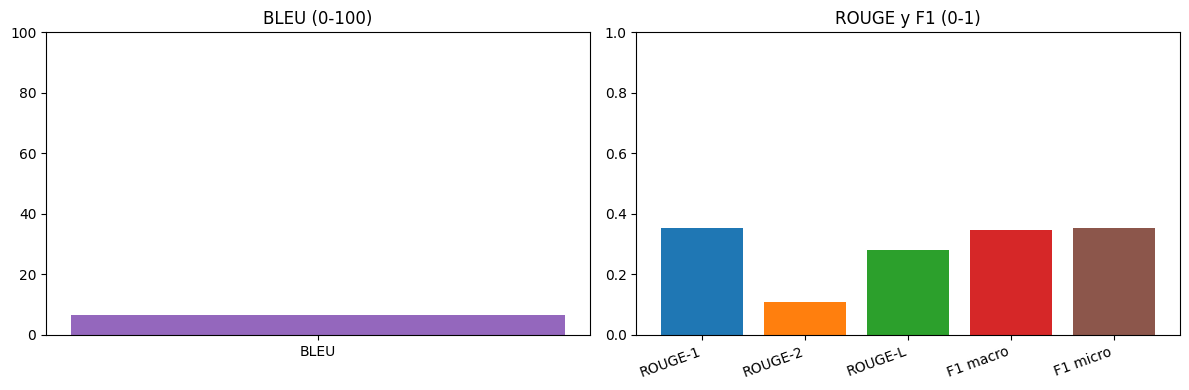

In [ ]:
# Gráfica resumen de métricas
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(["BLEU"], [metricas["bleu"]], color="tab:purple")
axes[0].set_ylim(0, 100)
axes[0].set_title("BLEU (0-100)")

nombres = ["ROUGE-1", "ROUGE-2", "ROUGE-L", "F1 macro", "F1 micro"]
valores = [metricas["rouge1_f1"], metricas["rouge2_f1"], metricas["rougeL_f1"],
           metricas["f1_macro"], metricas["f1_micro"]]
axes[1].bar(nombres, valores, color=["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:brown"])
axes[1].set_ylim(0, 1)
axes[1].set_title("ROUGE y F1 (0-1)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(FIGURAS / "mt_metricas.png", dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
# Guardar vocabularios (el modelo se puede volver a entrenar con este notebook)
(RESULTADOS / "vocab_es.json").write_text(json.dumps(vocab_es, ensure_ascii=False, indent=2), encoding="utf-8")
(RESULTADOS / "vocab_en.json").write_text(json.dumps(vocab_en, ensure_ascii=False, indent=2), encoding="utf-8")
print("Vocabularios guardados. El modelo no se incluye para mantener el ZIP liviano.")


Vocabularios guardados. El modelo no se incluye para mantener el ZIP liviano.
